## 1. Setup and Load Data
Import libraries and load the raw CSV from `data/raw/`.

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path(r"D:\Customer_Behavior\data\raw\shopping.csv")  # use your actual filename
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head() 

(3900, 18)


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


**Result:** 3,900 rows x 18 columns. Each row is one customer with one purchase.

## 2. Data Quality Checks
Check data types, missing values, duplicates, and value ranges before doing any analysis.

In [81]:
df.info()
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["Customer ID"].duplicated().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   str    
 3   Item Purchased          3900 non-null   str    
 4   Category                3900 non-null   str    
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   str    
 7   Size                    3900 non-null   str    
 8   Color                   3900 non-null   str    
 9   Season                  3900 non-null   str    
 10  Review Rating           3900 non-null   float64
 11  Subscription Status     3900 non-null   str    
 12  Shipping Type           3900 non-null   str    
 13  Discount Applied        3900 non-null   str    
 14  Promo Code Used         3900 non-null   str    
 15

,count,mean,std,min,25%,50%,75%,max
Customer ID,3900.0,1950.500000,1125.977353,1.0,975.75,1950.5,2925.25,3900.0
Age,3900.0,44.068462,15.207589,18.0,31.00,44.0,57.00,70.0
Purchase Amount (USD),3900.0,59.764359,23.685392,20.0,39.00,60.0,81.00,100.0
Review Rating,3900.0,3.749949,0.716223,2.5,3.10,3.7,4.40,5.0
Previous Purchases,3900.0,25.351538,14.447125,1.0,13.00,25.0,38.00,50.0


**Findings**
- No missing values and no duplicate rows or duplicate Customer IDs.
- Age ranges from 18 to 70. Purchase amounts range up to $100, and review ratings run from 1 to 5.
- Data is clean, so the work is standardizing and feature engineering rather than fixing errors.

## 3. Cleaning and Feature Engineering
- Convert column names to snake_case for SQL and Streamlit compatibility.
- Merge duplicate frequency labels: `Bi-Weekly` -> `Fortnightly`, `Every 3 Months` -> `Quarterly`.
- Create `age_group` and `spend_bucket` for segmentation.
- Convert Yes/No columns to 1/0 flags for easy averages.

In [82]:
# snake_case column names (e.g. "Purchase Amount (USD)" -> "purchase_amount_usd")
df.columns = (
    df.columns.str.strip().str.lower()
    .str.replace(r"[^\w]+", "_", regex=True).str.strip("_")
)

# Same frequency appears under two names, so merge them
df["frequency_of_purchases"] = df["frequency_of_purchases"].replace(
    {"Bi-Weekly": "Fortnightly", "Every 3 Months": "Quarterly"}
)

# Age groups and spend buckets
df["age_group"] = pd.cut(
    df["age"], bins=[17, 24, 34, 44, 54, 64, 100],
    labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"],
)
df["spend_bucket"] = pd.qcut(df["purchase_amount_usd"], 3, labels=["Low", "Medium", "High"])

# Yes/No columns to 1/0 for easy averages
for col in ["subscription_status", "discount_applied", "promo_code_used"]:
    df[col + "_flag"] = (df[col] == "Yes").astype(int)

print(df["frequency_of_purchases"].value_counts())
df.head()

frequency_of_purchases
Quarterly      1147
Fortnightly    1089
Annually        572
Monthly         553
Weekly          539
Name: count, dtype: int64


,customer_id,age,gender,item_purchased,category,purchase_amount_usd,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,promo_code_used,previous_purchases,payment_method,frequency_of_purchases,age_group,spend_bucket,subscription_status_flag,discount_applied_flag,promo_code_used_flag
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly,55-64,Medium,1,1,1
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly,18-24,Medium,1,1,1
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly,45-54,Medium,1,1,1
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly,18-24,High,1,1,1
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually,45-54,Medium,1,1,1


**Result:** Frequency now has 5 consistent categories instead of 7, and the dataset has 23 columns.

**Data limitation:** `Discount Applied` and `Promo Code Used` are identical in every row, so they carry the same information. I treat them as one "promotion" signal in the analysis.

## 4. Q1: Which categories, items, and states drive revenue?
Total revenue, average order value, and order count by category, then the top 10 items and states.

,sum,mean,count
category,,,
Clothing,104264,60.025331,1737
Accessories,74200,59.838710,1240
Footwear,36093,60.255426,599
Outerwear,18524,57.172840,324


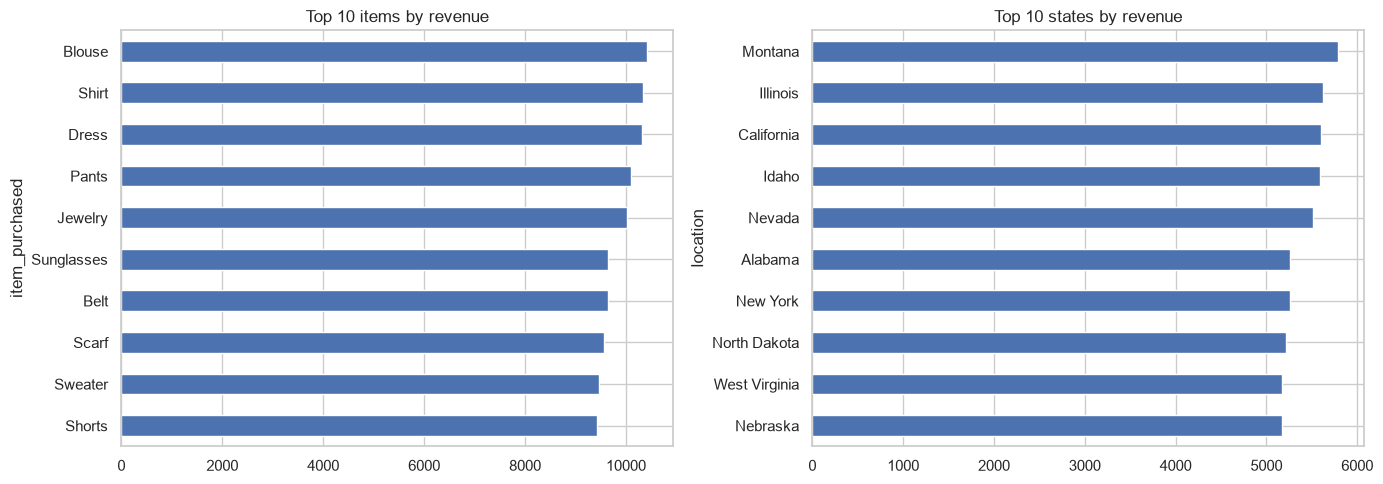

In [83]:
rev_cat = df.groupby("category")["purchase_amount_usd"].agg(["sum", "mean", "count"]).sort_values("sum", ascending=False)
display(rev_cat)

top_items = df.groupby("item_purchased")["purchase_amount_usd"].sum().sort_values(ascending=False).head(10)
top_states = df.groupby("location")["purchase_amount_usd"].sum().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
top_items.sort_values().plot.barh(ax=ax[0], title="Top 10 items by revenue")
top_states.sort_values().plot.barh(ax=ax[1], title="Top 10 states by revenue")
plt.tight_layout(); plt.show()

**Findings**
- Total revenue is about $233K. **Clothing leads with 44.7%**, followed by Accessories (31.8%), Footwear (15.5%), and Outerwear (7.9%).
- Average order value is almost the same in every category (about $57-$60), so revenue differences come from **order volume**, not price.
- Top items are Blouse, Shirt, Dress, Pants, and Jewelry, each at roughly $10K. The spread across items is narrow.
- Top states: Montana, Illinois, California, Idaho, Nevada. Lowest: Kansas, Hawaii, Florida.

**Takeaway:** Clothing drives volume, and no single product or state dominates, so revenue is broadly spread.

## 5. Q2: How does season affect spend?
Revenue, average order value, and category mix by season.

,sum,mean,count
season,,,
Fall,60018,61.556923,975
Spring,58679,58.737738,999
Summer,55777,58.405236,955
Winter,58607,60.357364,971


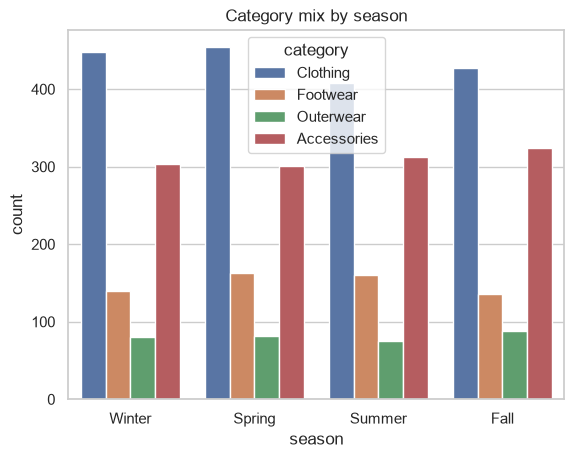

In [84]:
season = df.groupby("season")["purchase_amount_usd"].agg(["sum", "mean", "count"])
display(season)

sns.countplot(data=df, x="season", hue="category")
plt.title("Category mix by season"); plt.show()

**Findings**
- Fall has the highest revenue ($60.0K) and average order ($61.56). Summer is lowest ($55.8K, $58.41).
- Order counts are nearly equal across seasons (955-999), so there is **no strong seasonality**.
- Category mix is stable. Clothing is the largest category in every season.

**Takeaway:** Seasonal differences are small (about 7% between best and worst), so seasonal promotions are unlikely to move much on this evidence.

## 6. Q3: Do discounts and promo codes increase spend?
Compare average spend and rating with and without a discount or promo code. Since both columns are identical, the result is the same for each.

                 purchase_amount_usd       review_rating      
                                mean count          mean count
discount_applied                                              
No                             60.13  2223          3.76  2223
Yes                            59.28  1677          3.74  1677 

                purchase_amount_usd       review_rating      
                               mean count          mean count
promo_code_used                                              
No                            60.13  2223          3.76  2223
Yes                           59.28  1677          3.74  1677 



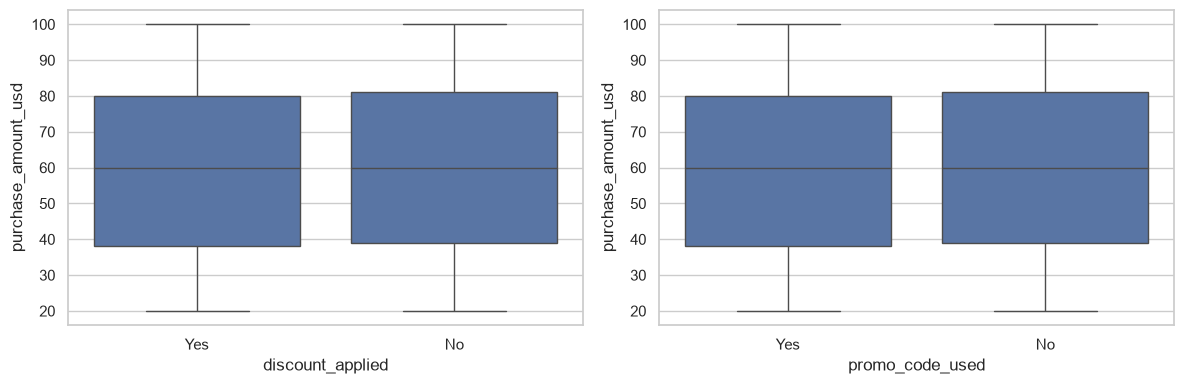

In [85]:
for col in ["discount_applied", "promo_code_used"]:
    print(df.groupby(col)[["purchase_amount_usd", "review_rating"]].agg(["mean", "count"]).round(2), "\n")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="discount_applied", y="purchase_amount_usd", ax=ax[0])
sns.boxplot(data=df, x="promo_code_used", y="purchase_amount_usd", ax=ax[1])
plt.tight_layout(); plt.show()

**Findings**
- 43% of customers (1,677) used a discount/promo code.
- Average spend is **$59.28 with a discount vs. $60.13 without**, and ratings are 3.74 vs. 3.76.
- Discounted purchases are not larger and do not get better reviews.

**Takeaway:** On this data, discounts show no spend lift. Statistical testing in Notebook 2 will confirm whether the small gap is just noise.

## 7. Q4: Are subscribers more valuable?
Compare customer count, spend, rating, and previous purchases by subscription status.

In [86]:
sub = df.groupby("subscription_status").agg(
    customers=("customer_id", "count"),
    avg_spend=("purchase_amount_usd", "mean"),
    avg_rating=("review_rating", "mean"),
    avg_prev_purchases=("previous_purchases", "mean"),
).round(2)
display(sub)

,customers,avg_spend,avg_rating,avg_prev_purchases
subscription_status,,,,
No,2847,59.87,3.75,25.08
Yes,1053,59.49,3.74,26.08


**Findings**
- Only 27% of customers (1,053) are subscribers.
- Subscribers spend about the same ($59.49 vs. $59.87) and rate similarly (3.74 vs. 3.75).
- Subscribers have slightly more previous purchases (26.1 vs. 25.1).

**Takeaway:** Subscription doesn't show higher spend per order. Any value would come from repeat purchases, which this data only weakly supports.

## 8. Q6: Which products have low ratings?
Average rating per item, with order count and revenue for context.

,avg_rating,orders,revenue
item_purchased,,,
Shirt,3.63,169,10332
Jeans,3.65,124,7548
Blouse,3.68,171,10410
Scarf,3.70,157,9561
Shorts,3.71,157,9433
Pants,3.72,171,10090
Hoodie,3.72,151,8767
Coat,3.73,161,9275


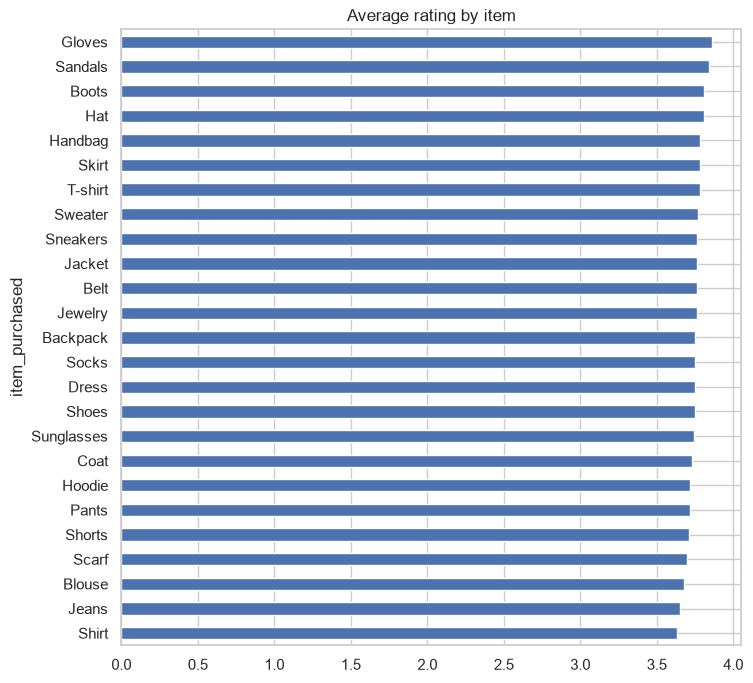

In [87]:
items = df.groupby("item_purchased").agg(
    avg_rating=("review_rating", "mean"),
    orders=("customer_id", "count"),
    revenue=("purchase_amount_usd", "sum"),
).round(2).sort_values("avg_rating")
display(items.head(8))

items["avg_rating"].sort_values().plot.barh(figsize=(8, 8), title="Average rating by item")
plt.show()

**Findings**
- Lowest rated: Shirt (3.63), Jeans (3.65), Blouse (3.68).
- Highest rated: Gloves (3.86), Sandals (3.84), Boots (3.81).
- The full range is only about 0.2 points, and Shirt and Blouse are also top revenue items.

**Takeaway:** Quality issues aren't severe, but the best-selling Shirt and Blouse are worth monitoring because they combine high volume with below-average ratings.

## 9. Q7: Shipping, payment method, and demographics
Compare spend and rating by shipping type and payment method, plus average spend by age group and gender.

In [88]:
for col in ["shipping_type", "payment_method"]:
    print(df.groupby(col)[["purchase_amount_usd", "review_rating"]].mean().round(2).sort_values("purchase_amount_usd", ascending=False), "\n")

# Bonus: who buys, by age group and gender
display(df.pivot_table(index="age_group", columns="gender", values="purchase_amount_usd", aggfunc="mean", observed=True).round(2))

                purchase_amount_usd  review_rating
shipping_type                                     
2-Day Shipping                60.73           3.76
Express                       60.48           3.78
Free Shipping                 60.41           3.72
Store Pickup                  59.89           3.71
Next Day Air                  58.63           3.72
Standard                      58.46           3.82 

                purchase_amount_usd  review_rating
payment_method                                    
Debit Card                    60.92           3.76
Credit Card                   60.07           3.78
Bank Transfer                 59.71           3.70
Cash                          59.70           3.75
PayPal                        59.25           3.75
Venmo                         58.95           3.75 



gender,Female,Male
age_group,,
18-24,60.39,60.11
25-34,62.13,59.20
35-44,59.26,59.79
45-54,58.97,61.03
55-64,60.60,57.82
65+,60.21,59.49


**Findings**
- Shipping: average spend ranges from $58.46 (Standard) to $60.73 (2-Day). Standard shipping has the best rating (3.82).
- Payment: spend ranges from $58.95 (Venmo) to $60.92 (Debit Card), with ratings of 3.70-3.78.
- 68% of customers are male (2,652 vs. 1,248 female), but average spend is similar (about $59.54 vs. $60.25).

**Takeaway:** Differences are small everywhere. The gender split is the clearest pattern, and it affects who the business is reaching, not how much each person spends.

## 10. Save Processed Data
Export the cleaned dataset with engineered features to `data/processed/` for use in SQL, Power BI, Streamlit, and Notebook 2.

In [89]:
OUT_PATH = Path(r"D:\Customer_Behavior\data\processed\shopping_clean.csv")
df.to_csv(OUT_PATH, index=False)
print("Saved:", OUT_PATH, df.shape)

Saved: D:\Customer_Behavior\data\processed\shopping_clean.csv (3900, 23)


**Saved:** `data/processed/shopping_clean.csv` (3,900 rows x 23 columns).

## Summary of Findings
1. Revenue comes from order volume, not price: Clothing is 45% of revenue, and average order value is about $60 everywhere.
2. Seasonality, shipping, payment method, and gender show only small differences.
3. Discounts/promo codes and subscriptions show **no spend lift** at first look.
4. Customer behavior looks fairly uniform, so Notebook 2 will use segmentation and statistical tests to look for patterns that averages hide.

**Next:** Notebook 2 for hypothesis tests and K-Means segmentation.